# Reproduction NC Grokking

In [1]:
import itertools
import matplotlib.pyplot as plt
import polars as pl
import polars.selectors as cs

from datetime import date
from matplotlib.ticker import MultipleLocator, EngFormatter
from privacy_and_grokking.artifacts.local import get_plots_dir
from shared import setup, SETUPS, preprocess_metrics_df

In [2]:
setup()

In [4]:
metrics_df = pl.read_parquet("../../cache/reproduction-nc-grokking-v1_mlflow_export.parquet")
metrics_df = preprocess_metrics_df(metrics_df)

## Overview

In [5]:
metrics_df.head()

run_id,run_name,step,timestamp,epoch,train/total_loss,train/task_loss,eval/generalization_gap,eval/weight_norm/total,eval/weight_norm/fc1.bias,eval/weight_norm/fc2.weight,eval/weight_norm/fc1.weight,eval/weight_norm/fc3.weight,eval/weight_norm/fc3.bias,eval/weight_norm/fc2.bias,eval/loss/mse/overlap,eval/loss/ce/overlap,eval/nc/nc1,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc2_equinorm_weights,eval/nc/nc3,eval/nc/nc4_test,eval/nc/nc4,eval/nc/rnc1/test,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/train,eval/nc/rnc1/train_impl,eval/nc/rnc1/test_impl,eval/attack/correctness/auc,eval/attack/correctness/tpr-at-fpr/10,eval/attack/correctness/tpr-at-fpr/5,eval/attack/correctness/tpr-at-fpr/1,…,eval/weight_norm/attn.out_proj.weight,eval/weight_norm/mlp.0.weight,eval/weight_norm/head.weight,eval/weight_norm/attn.in_proj_weight,eval/weight_norm/token_embed.weight,eval/weight_norm/attn.out_proj.bias,eval/weight_norm/attn.in_proj_bias,eval/weight_norm/mlp.2.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.heads.head.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.class_token,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.conv_proj.weight,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,title
str,str,i64,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""06a2cc5d220248c788893187682a76…","""NO_GROK_MNIST_CE_MLP""",0,2026-09-05 18:09:03.243,null,null,null,-0.00052,11.703523,0.288944,8.150558,8.177094,1.804869,0.12293,0.565521,0.96086,0.96238,2.18602,0.108467,0.292657,0.219871,0.078228,0.219103,0.031896,2.011329,0.8979,0.89692,0.111938,0.347369,0.106921,0.107356,0.349725,0.343135,0.49974,0.099493,0.049747,0.009949,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""(IV) MLP (CE) No Grokking"""
"""06a2cc5d220248c788893187682a76…","""NO_GROK_MNIST_CE_MLP""",0,2026-09-05 18:09:07.044,0.0,null,null,-0.00052,11.703523,0.288944,8.150558,8.177094,1.804869,0.12293,0.565521,0.96086,0.96238,2.18602,0.108467,0.292657,0.219871,0.078228,0.219103,0.031896,2.011329,0.8979,0.89692,0.111938,0.347369,0.106921,0.107356,0.349725,0.343135,0.49974,0.099493,0.049747,0.009949

In [6]:
metrics_df.describe()

statistic,run_id,run_name,step,timestamp,epoch,train/total_loss,train/task_loss,eval/generalization_gap,eval/weight_norm/total,eval/weight_norm/fc1.bias,eval/weight_norm/fc2.weight,eval/weight_norm/fc1.weight,eval/weight_norm/fc3.weight,eval/weight_norm/fc3.bias,eval/weight_norm/fc2.bias,eval/loss/mse/overlap,eval/loss/ce/overlap,eval/nc/nc1,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc2_equinorm_weights,eval/nc/nc3,eval/nc/nc4_test,eval/nc/nc4,eval/nc/rnc1/test,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/train,eval/nc/rnc1/train_impl,eval/nc/rnc1/test_impl,eval/attack/correctness/auc,eval/attack/correctness/tpr-at-fpr/10,eval/attack/correctness/tpr-at-fpr/5,…,eval/weight_norm/attn.out_proj.weight,eval/weight_norm/mlp.0.weight,eval/weight_norm/head.weight,eval/weight_norm/attn.in_proj_weight,eval/weight_norm/token_embed.weight,eval/weight_norm/attn.out_proj.bias,eval/weight_norm/attn.in_proj_bias,eval/weight_norm/mlp.2.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.heads.head.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.class_token,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.conv_proj.weight,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,title
str,str,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""","""30432""","""30432""",30432.0,"""30432""",11592.0,7200.0,7200.0,23232.0,23232.0,11856.0,11856.0,11856.0,11856.0,11856.0,11856.0,23232.0,23232.0,18744.0,18744.0,18744.0,18744.0,18744.0,18744.0,18720.0,18720.0,18744.0,18744.0,18744.0,18744.0,18744.0,18744.0,18744.0,18744.0,23232.0,23232.0,23232.0,…,5448.0,5448.0,5448.0,5448.0,5448.0,5448.0,5448.0,5448.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5928.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,5904.0,"""27078"""
"""null_count""","""0""","""0""",0.0,"""0""",18840.0,23232.0,23232.0,7200.0,7200.0,18576.0,18576.0,18576.0,18576.0,18576.0,18576.0,7200.0,7200.0,11688.0,11688.0,11688.0,11688.0,11688.0,11688.0,11712.0,11712.0,11688.0,11688.0,11688.0,11688.0,11688.0,11688.0,11688.0,11688.0,7200.0,7200.0,7200.0,…,24984.0,24984.0,24984.0,24984.0,24984.0,24984.0,24984.0,24984.0,24504.0,24504.0,24504.0,24504.0,24504.0,24504.

In [7]:
metrics_df.columns

['run_id',
 'run_name',
 'step',
 'timestamp',
 'epoch',
 'train/total_loss',
 'train/task_loss',
 'eval/generalization_gap',
 'eval/weight_norm/total',
 'eval/weight_norm/fc1.bias',
 'eval/weight_norm/fc2.weight',
 'eval/weight_norm/fc1.weight',
 'eval/weight_norm/fc3.weight',
 'eval/weight_norm/fc3.bias',
 'eval/weight_norm/fc2.bias',
 'eval/loss/mse/overlap',
 'eval/loss/ce/overlap',
 'eval/nc/nc1',
 'eval/nc/nc2_maximal_angle_equiangularity_weights',
 'eval/nc/nc2_equiangularity',
 'eval/nc/nc2_equinorm',
 'eval/nc/nc2_equiangularity_weights',
 'eval/nc/nc2_maximal_angle_equiangularity',
 'eval/nc/nc2_equinorm_weights',
 'eval/nc/nc3',
 'eval/nc/nc4_test',
 'eval/nc/nc4',
 'eval/nc/rnc1/test',
 'eval/nc/rnc1/train_mean_test_variance_impl',
 'eval/nc/rnc1/train_mean_test_variance',
 'eval/nc/rnc1/train',
 'eval/nc/rnc1/train_impl',
 'eval/nc/rnc1/test_impl',
 'eval/attack/correctness/auc',
 'eval/attack/correctness/tpr-at-fpr/10',
 'eval/attack/correctness/tpr-at-fpr/5',
 'eval/atta

In [8]:
metrics_df.group_by("title").agg(pl.col("step").max())

title,step
str,i64
null,150000
"""(V) ViT (CE) Grokking""",150000
"""(IV) MLP (CE) No Grokking""",150000
"""(VII) MADD (CE) Grokking""",150000
"""(II) MLP (MSE) No Grokking""",150000
"""(III) MLP (CE) Grokking""",150000
"""(VI) ViT (CE) No Grokking""",150000
"""(I) MLP (MSE) Grokking""",150000


## Analysis

In [9]:
PLOTS = get_plots_dir()

## Neural Collapse Overview

Consolidated neural-collapse figure using the same uniform layout as `plot_canary_selection.ipynb`:
mean ± std across seeds, a rotated row title per model setup, column titles only on the top row,
and a shared step-axis format (25k ticks, `EngFormatter`).


In [10]:
N_COLS = 4
N_ROWS = len(SETUPS)
TITLES = list(SETUPS.values())
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]


def plot_region(ax, df, metric, label, **kwargs):
    """Plot the across-seed mean and its ±1 std band for one metric.

    Line-only kwargs (e.g. ``linestyle``) are intentionally not forwarded to the
    band; otherwise the uncertainty ribbon would get a dashed border as well.
    """
    line = ax.plot(df["step"], df[f"{metric}_mean"], label=label, **kwargs)[0]
    ax.fill_between(
        df["step"],
        df[f"{metric}_mean"] - df[f"{metric}_std"],
        df[f"{metric}_mean"] + df[f"{metric}_std"],
        color=line.get_color(),
        alpha=0.2,
    )
    return line


def style_step_axis(ax, df):
    """Apply the shared step-axis limits, locator, and formatter."""
    step_max = df["step"].max()
    ax.set_xlim(-0.05 * step_max, step_max * 1.05)
    ax.xaxis.set_major_locator(MultipleLocator(25_000 if step_max > 50_000 else 10_000))
    ax.xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))


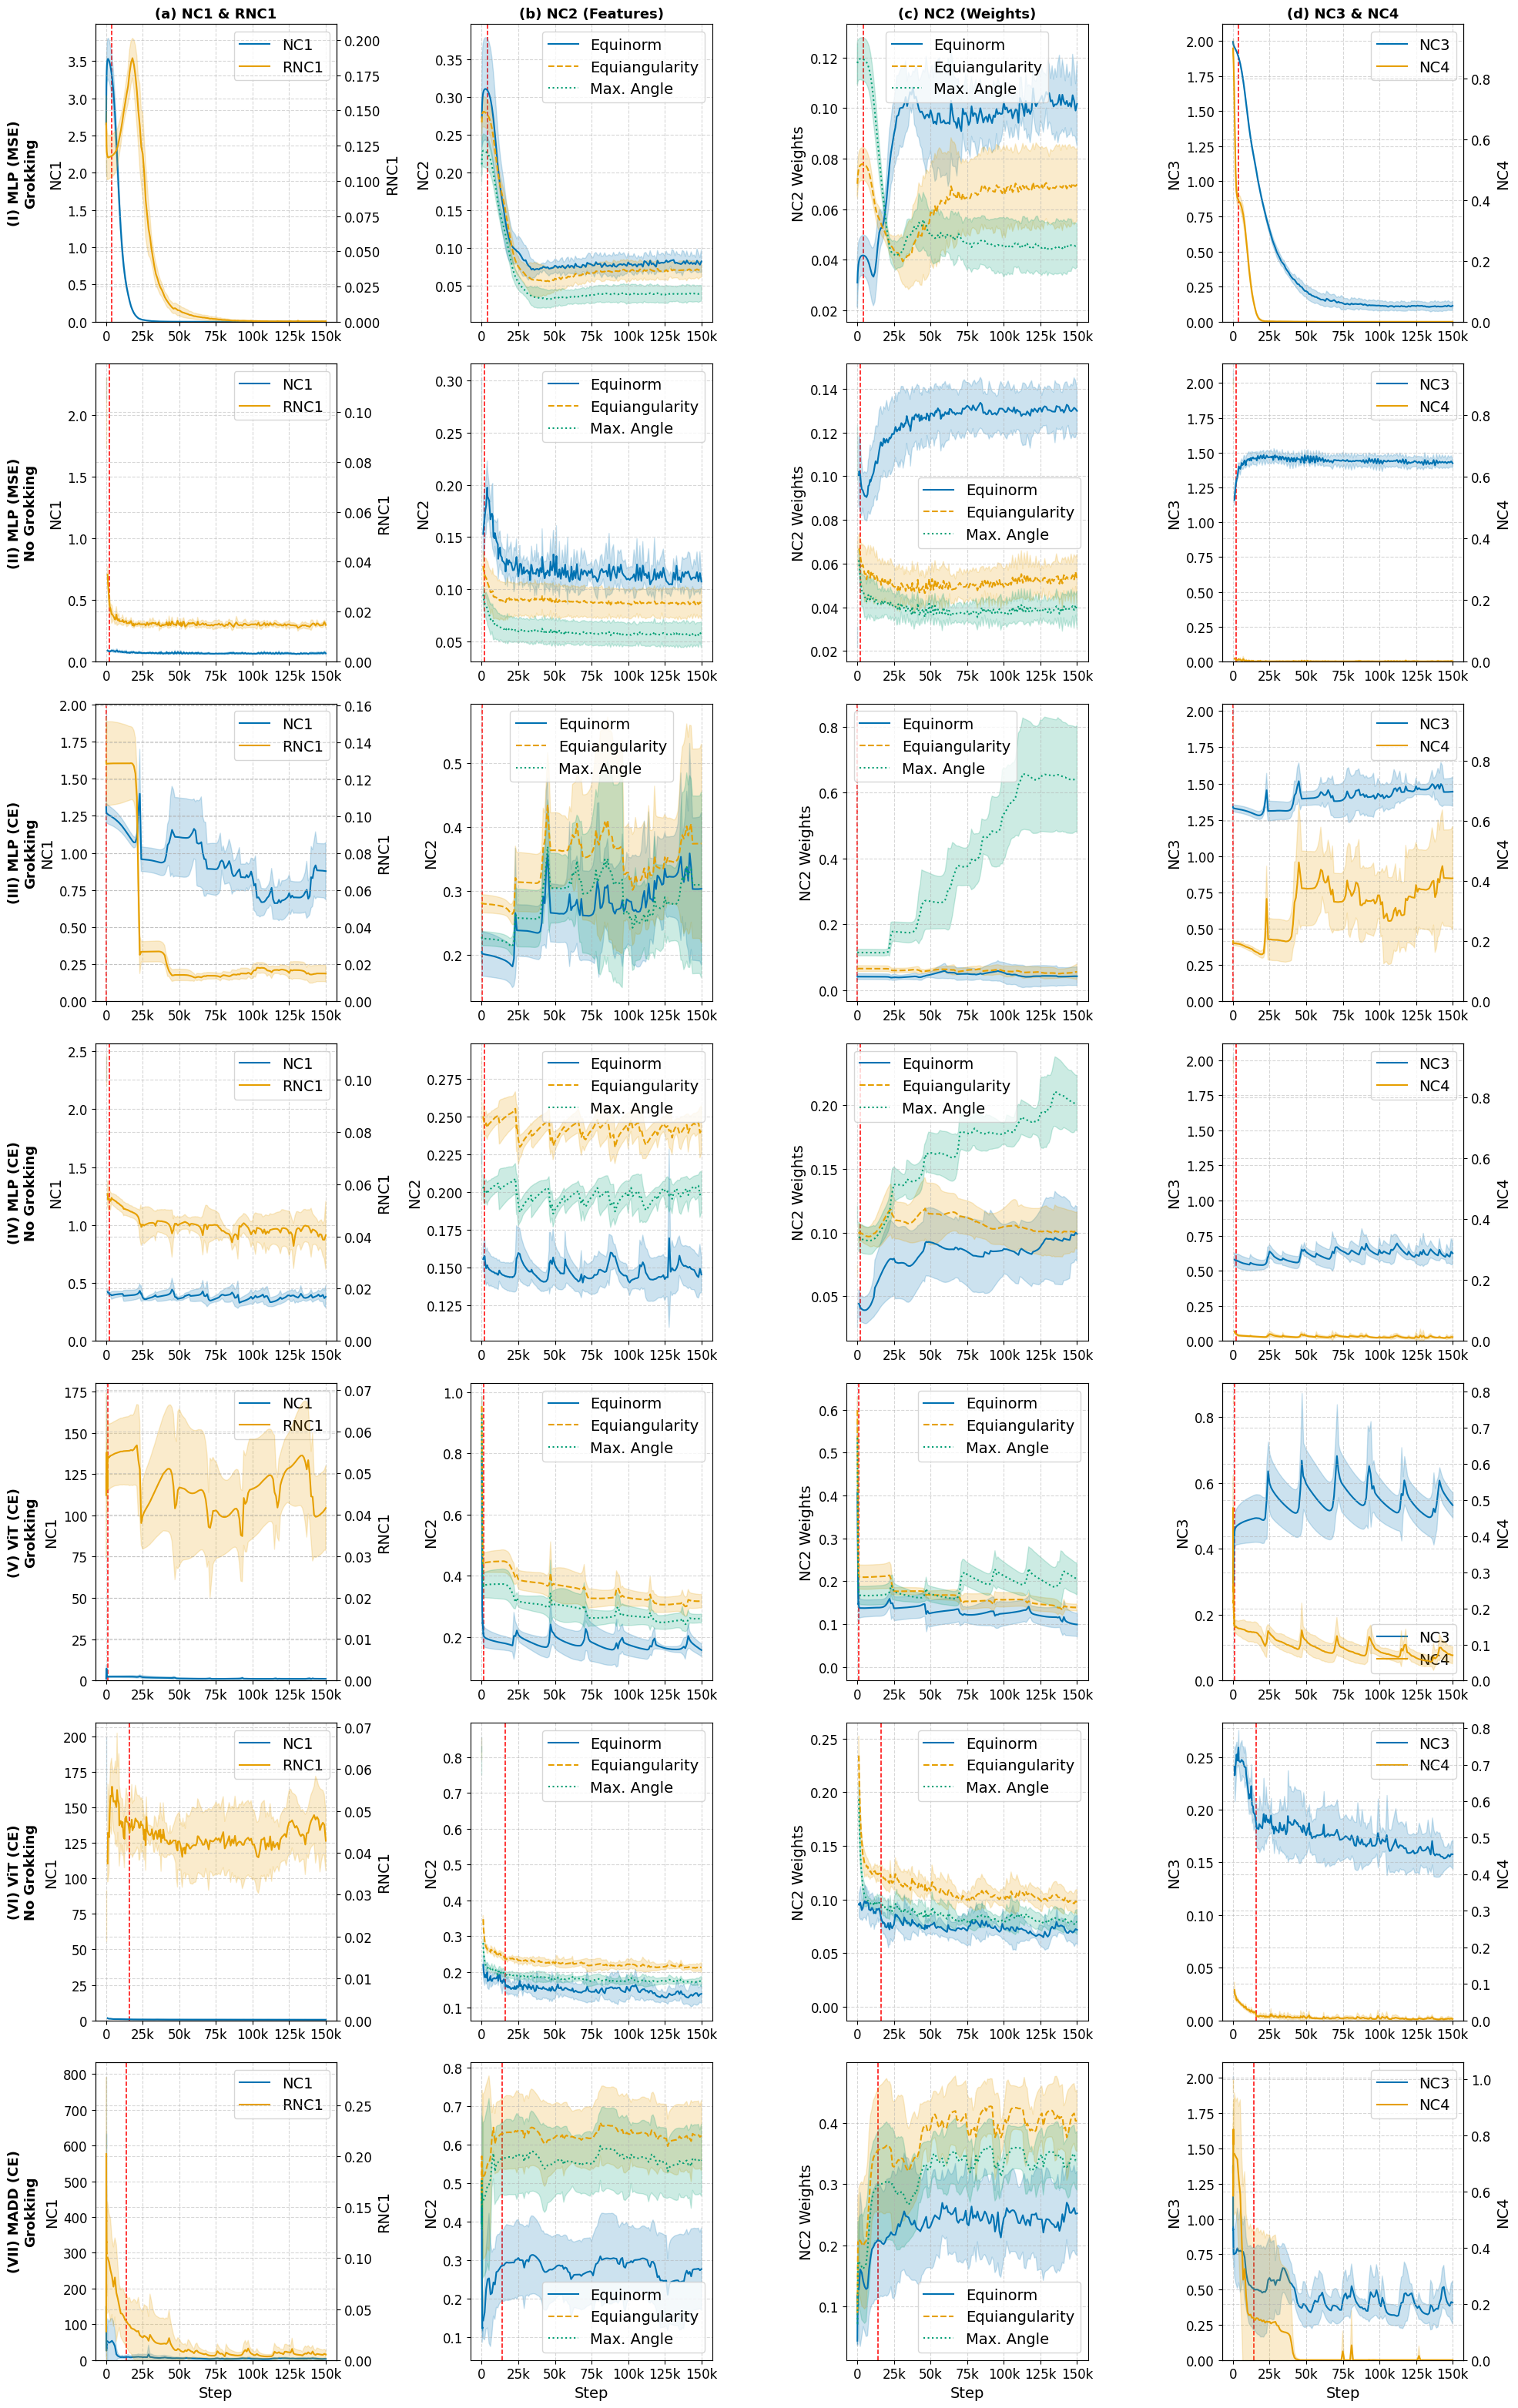

In [11]:
fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

for row, title in enumerate(TITLES):
    ax = axes[row]

    # Aggregate all seeds so every panel shows mean ± std like the canary overview.
    df = (
        metrics_df
        .filter(pl.col("title") == title)
        .group_by(["title", "step"])
        .agg([
            cs.numeric().exclude("step").mean().name.suffix("_mean"),
            cs.numeric().exclude("step").std().name.suffix("_std"),
        ])
        .sort(["title", "step"])
    )

    if df.is_empty():
        for a in ax:
            a.text(0.5, 0.5, "N/A", ha="center", va="center")
        continue

    # Red dashed line: first step at which the mean training accuracy saturates.
    train_acc = df.filter(pl.col("eval/train/accuracy_mean") >= 0.999)
    vline = train_acc["step"].min() if len(train_acc) else None

    for a in ax:
        style_step_axis(a, df)
        if vline is not None:
            a.axvline(x=vline, color="red", linestyle="--", linewidth=1.1, zorder=0)

    # Row title (rotated, left of the first panel).
    ax[0].annotate(
        title,
        xy=(-0.30, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )

    if row == N_ROWS - 1:
        for i in range(N_COLS):
            ax[i].set_xlabel("Step")

    # (a) NC1 (left axis) & RNC1 (right axis).
    if row == 0:
        ax[0].set_title("(a) NC1 & RNC1", fontsize=13, fontweight="bold")
    twin_a = ax[0].twinx()
    plot_region(ax[0], df, "eval/nc/nc1", "NC1", color=COLORS[0])
    plot_region(twin_a, df, "eval/nc/rnc1/train", "RNC1", color=COLORS[1], linestyle="--")
    ax[0].set_ylabel("NC1")
    twin_a.set_ylabel("RNC1")
    ax[0].set_ylim(bottom=0)
    twin_a.set_ylim(bottom=0)
    handles = ax[0].get_lines() + twin_a.get_lines()
    handles = [h for h in handles if not h.get_label().startswith("_")]
    ax[0].legend(handles, [h.get_label() for h in handles])

    # (b) NC2 (features).
    if row == 0:
        ax[1].set_title("(b) NC2 (Features)", fontsize=13, fontweight="bold")
    plot_region(ax[1], df, "eval/nc/nc2_equinorm", "Equinorm", color=COLORS[0])
    plot_region(ax[1], df, "eval/nc/nc2_equiangularity", "Equiangularity", color=COLORS[1])
    plot_region(ax[1], df, "eval/nc/nc2_maximal_angle_equiangularity", "Max. Angle", color=COLORS[2])
    ax[1].set_ylabel("NC2")
    ax[1].legend()

    # (c) NC2 (classifier weights).
    if row == 0:
        ax[2].set_title("(c) NC2 (Weights)", fontsize=13, fontweight="bold")
    plot_region(ax[2], df, "eval/nc/nc2_equinorm_weights", "Equinorm", color=COLORS[0])
    plot_region(ax[2], df, "eval/nc/nc2_equiangularity_weights", "Equiangularity", color=COLORS[1])
    plot_region(ax[2], df, "eval/nc/nc2_maximal_angle_equiangularity_weights", "Max. Angle", color=COLORS[2])
    ax[2].set_ylabel("NC2 Weights")
    ax[2].legend()

    # (d) NC3 (left axis) & NC4 (right axis).
    if row == 0:
        ax[3].set_title("(d) NC3 & NC4", fontsize=13, fontweight="bold")
    twin_d = ax[3].twinx()
    plot_region(ax[3], df, "eval/nc/nc3", "NC3", color=COLORS[0])
    plot_region(twin_d, df, "eval/nc/nc4", "NC4", color=COLORS[1], linestyle="--")
    ax[3].set_ylabel("NC3")
    twin_d.set_ylabel("NC4")
    ax[3].set_ylim(bottom=0)
    twin_d.set_ylim(bottom=0)
    handles = ax[3].get_lines() + twin_d.get_lines()
    handles = [h for h in handles if not h.get_label().startswith("_")]
    ax[3].legend(handles, [h.get_label() for h in handles])

plt.tight_layout()
fig.savefig(PLOTS / f"reproduction_nc_grokking_nc_metrics_{str(date.today())}.pdf", format="pdf", bbox_inches="tight")
fig.savefig(PLOTS / f"reproduction_nc_grokking_nc_metrics_{str(date.today())}.png", dpi=300, bbox_inches="tight")


## General Metrics Overview

Same uniform layout as above and as `plot_canary_selection.ipynb`: mean ± std across seeds,
rotated row titles, column titles only on the top row, and one shared step-axis format.

- **(a)** Train and Test Accuracy
- **(b)** Train and Test Loss (log scale; MSE or CE depending on the setup)
- **(c)** Total and last-layer weight norm


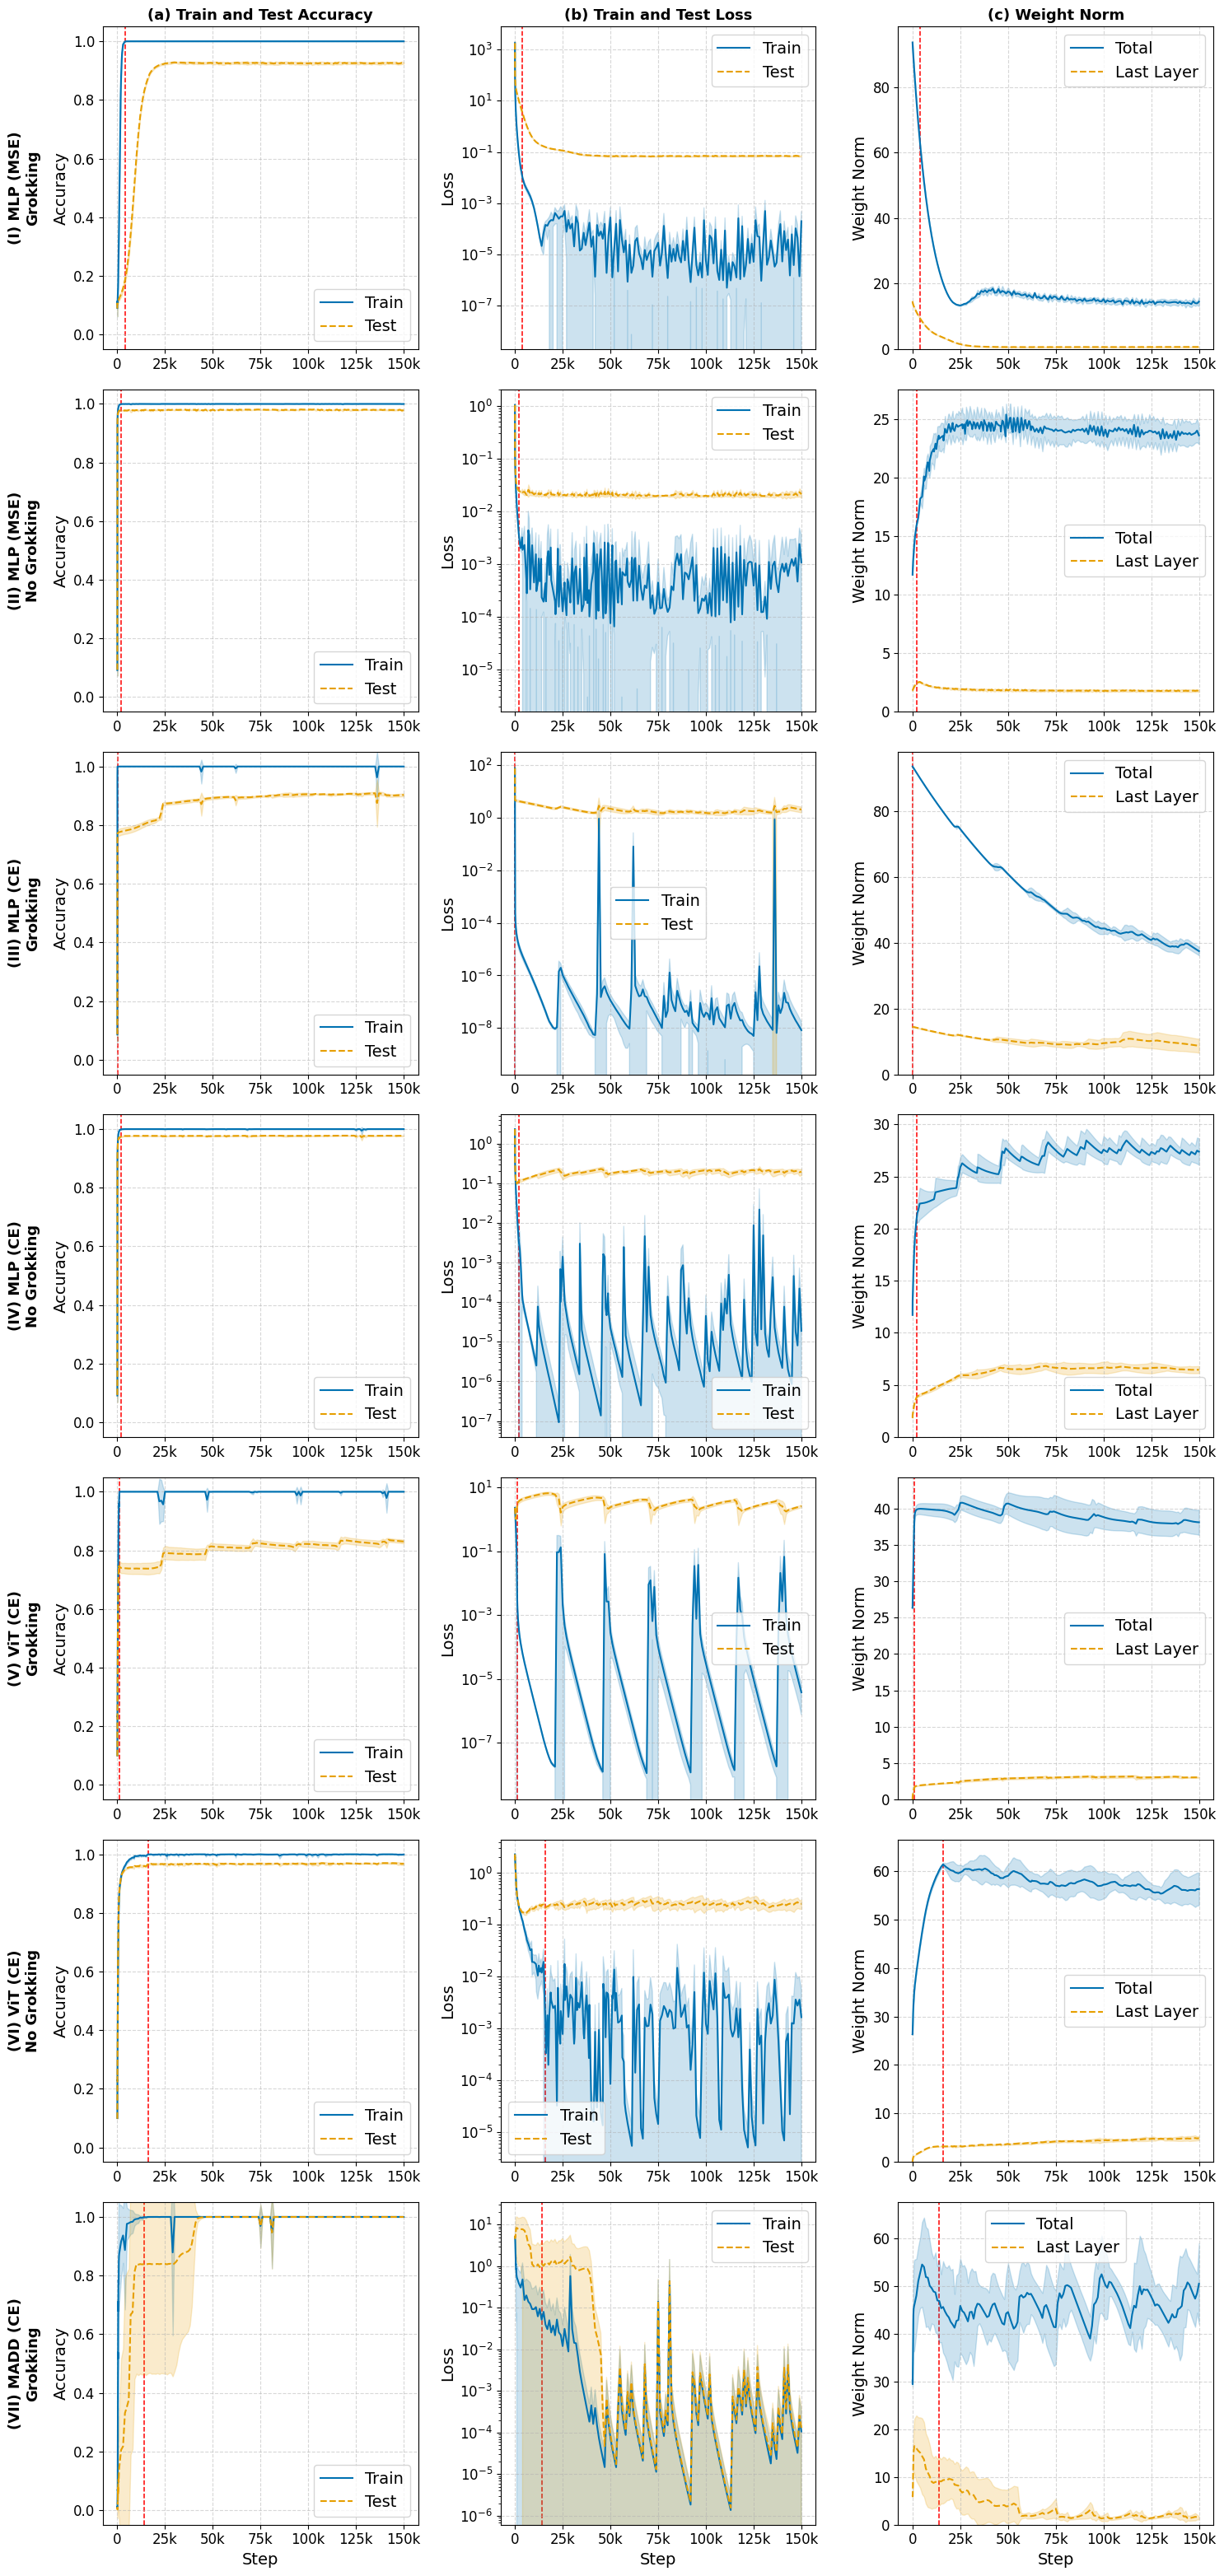

In [12]:
N_COLS = 3
N_ROWS = len(SETUPS)
TITLES = list(SETUPS.values())

LAST_LAYER_METRICS = {
    "MLP": "eval/weight_norm/fc3.weight",
    "ViT": "eval/weight_norm/vit.heads.head.weight",
    "MADD": "eval/weight_norm/head.weight",
}


def last_layer_metric(title):
    """Return the final-layer weight-norm metric that belongs to a setup."""
    for model, metric in LAST_LAYER_METRICS.items():
        if model in title:
            return metric
    return None


fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

for row, title in enumerate(TITLES):
    ax = axes[row]

    # Aggregate all seeds so every panel shows mean ± std like the canary overview.
    df = (
        metrics_df
        .filter(pl.col("title") == title)
        .group_by(["title", "step"])
        .agg([
            cs.numeric().exclude("step").mean().name.suffix("_mean"),
            cs.numeric().exclude("step").std().name.suffix("_std"),
        ])
        .sort(["title", "step"])
    )

    if df.is_empty():
        for a in ax:
            a.text(0.5, 0.5, "N/A", ha="center", va="center")
        continue

    # Red dashed line: first step at which the mean training accuracy saturates.
    train_acc = df.filter(pl.col("eval/train/accuracy_mean") >= 0.999)
    vline = train_acc["step"].min() if len(train_acc) else None

    for a in ax:
        style_step_axis(a, df)
        if vline is not None:
            a.axvline(x=vline, color="red", linestyle="--", linewidth=1.1, zorder=0)

    # Row title (rotated, left of the first panel).
    ax[0].annotate(
        title,
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )

    if row == N_ROWS - 1:
        for i in range(N_COLS):
            ax[i].set_xlabel("Step")

    # (a) Train and Test Accuracy.
    if row == 0:
        ax[0].set_title("(a) Train and Test Accuracy", fontsize=13, fontweight="bold")
    plot_region(ax[0], df, "eval/train/accuracy", "Train", color=COLORS[0])
    plot_region(ax[0], df, "eval/test/accuracy", "Test", color=COLORS[1])
    ax[0].set_ylabel("Accuracy")
    ax[0].set_ylim(-0.05, 1.05)
    ax[0].legend()

    # (b) Train and Test Loss. Select the loss that belongs to the setup.
    loss = "mse" if "mse" in title.lower() else "cross_entropy"
    if row == 0:
        ax[1].set_title("(b) Train and Test Loss", fontsize=13, fontweight="bold")
    plot_region(ax[1], df, f"eval/train/loss/{loss}/mean", "Train", color=COLORS[0])
    plot_region(ax[1], df, f"eval/test/loss/{loss}/mean", "Test", color=COLORS[1])
    ax[1].set_ylabel("Loss")
    ax[1].set_yscale("log")
    ax[1].legend()

    # (c) Total and last-layer weight norm.
    if row == 0:
        ax[2].set_title("(c) Weight Norm", fontsize=13, fontweight="bold")
    plot_region(ax[2], df, "eval/weight_norm/total", "Total", color=COLORS[0])
    last_layer = last_layer_metric(title)
    if last_layer:
        plot_region(ax[2], df, last_layer, "Last Layer", color=COLORS[1])
    ax[2].set_ylabel("Weight Norm")
    ax[2].set_ylim(bottom=0)
    ax[2].legend()

plt.tight_layout()
fig.savefig(PLOTS / f"reproduction_nc_grokking_general_metrics_{str(date.today())}.pdf", format="pdf", bbox_inches="tight")
fig.savefig(PLOTS / f"reproduction_nc_grokking_general_metrics_{str(date.today())}.png", dpi=300, bbox_inches="tight")
